# TV5 (Minh Thông) — Random Forest và đánh giá phân lớp

**Đề tài Khai thác dữ liệu: Dry Bean Dataset**

Notebook này dùng hai tập Train/Test đã được chuẩn bị và lưu trong `data/processed/`, giải thích Random Forest, tối ưu Random Forest/KNN/SVM bằng Stratified 10-fold CV với `f1_macro`, sau đó đánh giá SVM trên tập Test độc lập. Notebook không tự chia lại dữ liệu. Siêu tham số chỉ được chọn bằng tập Train; scaler của KNN và SVM nằm trong Pipeline để được fit riêng bên trong từng fold.

> Cần có `data/processed/train.csv` và `data/processed/test.csv` từ nhánh dùng chung. Có thể chạy notebook từ thư mục dự án hoặc `notebooks/`.

## 1. Thư viện và tải hai tập dữ liệu

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, f1_score
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

# Tìm thư mục gốc để notebook chạy được từ root dự án hoặc thư mục notebooks.
ROOT = next(
    (path for path in (Path.cwd(), *Path.cwd().parents)
     if (path / "data").is_dir() and (path / "notebooks").is_dir()),
    Path.cwd(),
)
TRAIN_FILE = ROOT / "data" / "processed" / "train.csv"
TEST_FILE = ROOT / "data" / "processed" / "test.csv"
FIGURES_DIR = ROOT / "outputs" / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

for data_file in (TRAIN_FILE, TEST_FILE):
    if not data_file.is_file():
        raise FileNotFoundError(
            f"Không tìm thấy {data_file}. "
            "Hãy cập nhật nhánh để lấy hai tập train.csv và test.csv."
        )

train_df = pd.read_csv(TRAIN_FILE)
test_df = pd.read_csv(TEST_FILE)
if "Class" not in train_df.columns or "Class" not in test_df.columns:
    raise ValueError("Cả train.csv và test.csv phải có cột nhãn 'Class'.")

feature_columns = [column for column in train_df.columns if column != "Class"]
test_feature_columns = [column for column in test_df.columns if column != "Class"]
if feature_columns != test_feature_columns:
    raise ValueError("Train và Test phải có cùng danh sách đặc trưng theo cùng thứ tự.")
if len(feature_columns) != 16:
    raise ValueError(f"Cần đúng 16 đặc trưng, hiện có {len(feature_columns)}.")

X_train = train_df[feature_columns].copy()
y_train = train_df["Class"].copy()
X_test = test_df[feature_columns].copy()
y_test = test_df["Class"].copy()
if not all(pd.api.types.is_numeric_dtype(dtype) for dtype in X_train.dtypes):
    raise TypeError("Tất cả 16 đặc trưng đầu vào phải có kiểu số.")
if not all(pd.api.types.is_numeric_dtype(dtype) for dtype in X_test.dtypes):
    raise TypeError("Tất cả 16 đặc trưng trong Test phải có kiểu số.")
if train_df.isna().any().any() or test_df.isna().any().any():
    raise ValueError("Train hoặc Test có giá trị thiếu; cần xử lý trước khi huấn luyện.")
if set(y_train.unique()) != set(y_test.unique()):
    raise ValueError("Train và Test phải chứa cùng các lớp nhãn.")

# Gộp chỉ để mô tả toàn bộ nhãn; việc huấn luyện/CV vẫn dùng riêng Train.
df = pd.concat([train_df, test_df], ignore_index=True)
X = df[feature_columns]
y = df["Class"]

print(f"Kích thước dữ liệu: {df.shape[0]:,} mẫu × {X.shape[1]} đặc trưng")
print(f"Số lớp: {y.nunique()} — {', '.join(map(str, sorted(y.unique())))}")
print("Phân bố lớp toàn bộ dữ liệu:")
display(y.value_counts().sort_index().rename("Số mẫu").to_frame())

Kích thước dữ liệu: 13,611 mẫu × 16 đặc trưng
Số lớp: 7 — BARBUNYA, BOMBAY, CALI, DERMASON, HOROZ, SEKER, SIRA
Phân bố lớp toàn bộ dữ liệu:


,Số mẫu
Class,
BARBUNYA,1322
BOMBAY,522
CALI,1630
DERMASON,3546
HOROZ,1928
SEKER,2027
SIRA,2636


### Kiểm tra hai tập và thiết lập kiểm định chéo

Train và Test được đọc từ hai file do thành viên phụ trách chuẩn bị; notebook không gọi `train_test_split` hay chia lại dữ liệu. Tập Test được giữ đến bước đánh giá cuối. Mọi GridSearchCV bên dưới dùng cùng cấu hình Stratified 10-fold trên riêng tập Train.

In [2]:
cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)

print(f"Train: {X_train.shape[0]:,} mẫu ({X_train.shape[0] / len(df):.1%})")
print(f"Test : {X_test.shape[0]:,} mẫu ({X_test.shape[0] / len(df):.1%})")
print("Tỷ lệ lớp trong Train:")
display(y_train.value_counts(normalize=True).sort_index().rename("Train"))
print("Tỷ lệ lớp trong Test:")
display(y_test.value_counts(normalize=True).sort_index().rename("Test"))

Train: 10,888 mẫu (80.0%)
Test : 2,723 mẫu (20.0%)
Tỷ lệ lớp trong Train:


Class
BARBUNYA    0.097079
BOMBAY      0.038391
CALI        0.119765
DERMASON    0.260562
HOROZ       0.141624
SEKER       0.148880
SIRA        0.193699
Name: Train, dtype: float64

Tỷ lệ lớp trong Test:


Class
BARBUNYA    0.097319
BOMBAY      0.038193
CALI        0.119721
DERMASON    0.260375
HOROZ       0.141755
SEKER       0.149100
SIRA        0.193537
Name: Test, dtype: float64

## 2. CLS-06 — Cơ sở lý thuyết Random Forest

**Ensemble Learning** kết hợp dự đoán của nhiều mô hình cơ sở để tạo một mô hình tổng hợp ổn định hơn. Với bài toán phân lớp, Random Forest tổng hợp phiếu dự đoán của nhiều cây quyết định (đa số phiếu).

**Bagging (Bootstrap Aggregating)** tạo nhiều tập huấn luyện bootstrap bằng cách lấy mẫu có hoàn lại từ dữ liệu Train. Mỗi cây được huấn luyện trên một mẫu bootstrap khác nhau; tổng hợp các cây giúp giảm phương sai và hạn chế hiện tượng một cây đơn lẻ quá khớp. Các bootstrap chỉ được tạo từ phần Train của mỗi fold, không dùng Test.

**Random Feature Subspace** chọn ngẫu nhiên một tập con đặc trưng khi tìm phép chia tại mỗi nút. Cơ chế này làm các cây ít tương quan hơn và tăng hiệu quả của việc bỏ phiếu. Với Dry Bean, các phép đo kích thước, hình dạng, biên và độ tròn có quan hệ với nhau; chọn tập con đặc trưng giúp đa dạng hóa các cây.

- `n_estimators`: số cây trong rừng; tăng số cây thường làm dự đoán ổn định hơn nhưng tăng thời gian và bộ nhớ.
- `max_depth`: độ sâu tối đa của cây; giới hạn độ sâu giúp kiểm soát độ phức tạp/overfit, còn `None` cho phép cây phát triển đến khi không thể chia tiếp.
- `min_samples_split`: số mẫu tối thiểu cần có tại một nút để tiếp tục chia; tăng giá trị này làm cây ít phức tạp hơn.

**Ưu điểm với Dry Bean:** mô hình hóa quan hệ phi tuyến và tương tác giữa các đặc trưng mà không cần chuẩn hóa; bagging thường giúp giảm overfit so với một cây sâu. **Hạn chế:** tìm kiếm nhiều tổ hợp cây tiêu tốn thời gian/tính toán, và rừng khó diễn giải hơn một cây đơn lẻ. Độ ổn định và mức độ phân loại nhầm giữa các giống vẫn cần được xác nhận bằng CV và tập Test.

## 3. CLS-07 — Tối ưu Random Forest bằng GridSearchCV

Tìm kiếm 12 tổ hợp tham số trên 10 fold phân tầng. Tiêu chí lựa chọn duy nhất là `f1_macro`, tức trung bình F1 của từng lớp nên các lớp có trọng số như nhau.

In [3]:
param_grid_rf = {
    "n_estimators": [100, 200],
    "max_depth": [15, 20, None],
    "min_samples_split": [2, 5],
}
rf_search = GridSearchCV(
    estimator=RandomForestClassifier(random_state=42),
    param_grid=param_grid_rf,
    scoring="f1_macro",
    cv=cv,
    n_jobs=1,
    refit=True,
    return_train_score=False,
)
rf_search.fit(X_train, y_train)

print("Tham số Random Forest tốt nhất:", rf_search.best_params_)
print(f"F1-macro trung bình 10-fold CV tốt nhất: {rf_search.best_score_:.4f}")

Tham số Random Forest tốt nhất: {'max_depth': 15, 'min_samples_split': 5, 'n_estimators': 100}
F1-macro trung bình 10-fold CV tốt nhất: 0.9360


## 4. CLS-08 — So sánh KNN, Random Forest và SVM

KNN và SVM được đóng gói cùng `StandardScaler` trong Pipeline; do đó scaler chỉ được fit trên phần huấn luyện của từng fold, tránh rò rỉ thông tin. Các GridSearchCV dùng cùng `cv` và tập Train. Random Forest đã được tìm kiếm ở mục trước và được đưa vào bảng so sánh dưới đây.

In [4]:
knn_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", KNeighborsClassifier()),
])
param_grid_knn = {
    "classifier__n_neighbors": [5, 9, 13, 17, 21],
    "classifier__weights": ["uniform", "distance"],
}
knn_search = GridSearchCV(
    estimator=knn_pipeline,
    param_grid=param_grid_knn,
    scoring="f1_macro",
    cv=cv,
    n_jobs=1,
    refit=True,
    return_train_score=False,
)
knn_search.fit(X_train, y_train)

svm_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", SVC()),
])
param_grid_svm = {
    "classifier__C": [1, 10, 100],
    "classifier__kernel": ["rbf"],
    "classifier__gamma": ["scale", "auto"],
}
svm_search = GridSearchCV(
    estimator=svm_pipeline,
    param_grid=param_grid_svm,
    scoring="f1_macro",
    cv=cv,
    n_jobs=1,
    refit=True,
    return_train_score=False,
)
svm_search.fit(X_train, y_train)

comparison = pd.DataFrame([
    {
        "Mô hình": "KNN",
        "Tham số tối ưu": knn_search.best_params_,
        "F1-macro 10-fold CV": knn_search.best_score_,
    },
    {
        "Mô hình": "Random Forest",
        "Tham số tối ưu": rf_search.best_params_,
        "F1-macro 10-fold CV": rf_search.best_score_,
    },
    {
        "Mô hình": "SVM",
        "Tham số tối ưu": svm_search.best_params_,
        "F1-macro 10-fold CV": svm_search.best_score_,
    },
]).sort_values("F1-macro 10-fold CV", ascending=False).reset_index(drop=True)
comparison.insert(0, "Xếp hạng", np.arange(1, len(comparison) + 1))
display(comparison)

,Xếp hạng,Mô hình,Tham số tối ưu,F1-macro 10-fold CV
0,1,SVM,"{'classifier__C': 10, 'classifier__gamma': 'sc...",0.944081
1,2,KNN,"{'classifier__n_neighbors': 21, 'classifier__w...",0.937921
2,3,Random Forest,"{'max_depth': 15, 'min_samples_split': 5, 'n_e...",0.935951


## 5. CLS-09 — Đánh giá SVM trên Test độc lập

Theo yêu cầu, sử dụng SVM với tham số tốt nhất đã chọn chỉ từ CV trên tập Train. `best_estimator_` được refit trên toàn bộ Train bởi GridSearchCV; tập Test chỉ được dùng ở đây để dự đoán và đánh giá một lần.

F1-macro trên Test độc lập (2,723 mẫu): 0.9361

Classification report (Precision, Recall, F1-score):
              precision    recall  f1-score   support

    BARBUNYA     0.9341    0.9094    0.9216       265
      BOMBAY     1.0000    1.0000    1.0000       104
        CALI     0.9388    0.9417    0.9403       326
    DERMASON     0.9097    0.9238    0.9167       709
       HOROZ     0.9609    0.9560    0.9584       386
       SEKER     0.9438    0.9507    0.9472       406
        SIRA     0.8733    0.8634    0.8683       527

    accuracy                         0.9243      2723
   macro avg     0.9372    0.9350    0.9361      2723
weighted avg     0.9243    0.9243    0.9243      2723



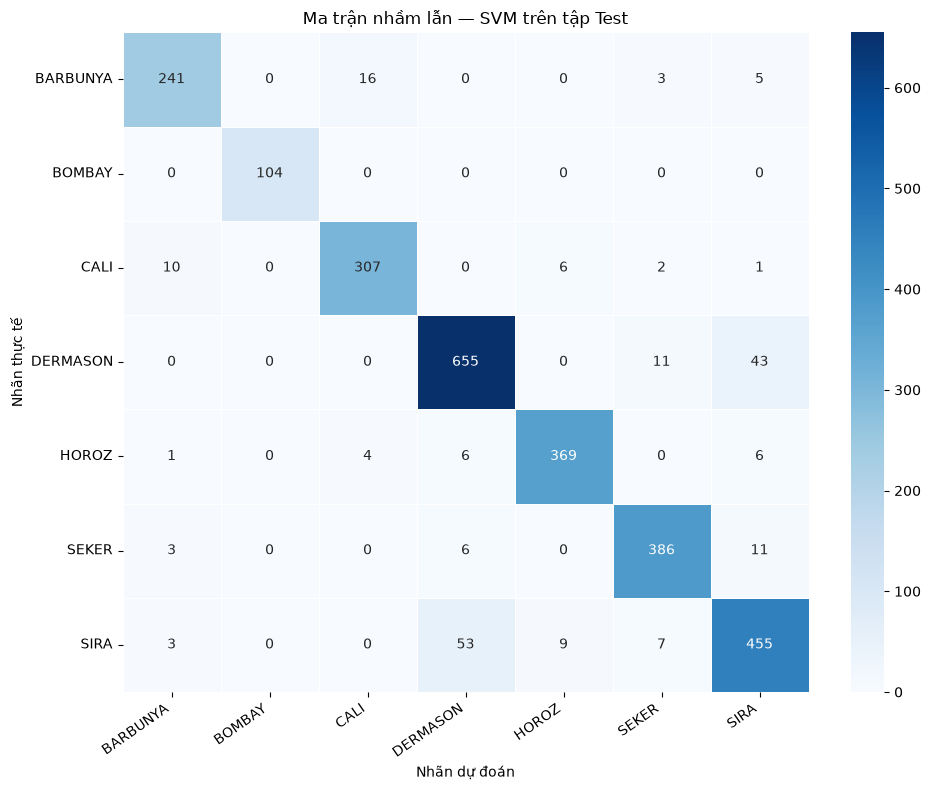

Đã lưu ma trận nhầm lẫn tại: outputs/figures/confusion_matrix_svm.png
Các hướng nhầm lẫn nhiều nhất (thực tế → dự đoán):
SIRA → DERMASON: 53 mẫu
DERMASON → SIRA: 43 mẫu
BARBUNYA → CALI: 16 mẫu
SEKER → SIRA: 11 mẫu
DERMASON → SEKER: 11 mẫu
CALI → BARBUNYA: 10 mẫu
SIRA → HOROZ: 9 mẫu
SIRA → SEKER: 7 mẫu
HOROZ → SIRA: 6 mẫu
SEKER → DERMASON: 6 mẫu


In [5]:
svm_model = svm_search.best_estimator_
y_pred = svm_model.predict(X_test)
labels = sorted(y.unique())

test_f1_macro = f1_score(y_test, y_pred, average="macro")
print(f"F1-macro trên Test độc lập ({len(y_test):,} mẫu): {test_f1_macro:.4f}")
print("\nClassification report (Precision, Recall, F1-score):")
print(classification_report(y_test, y_pred, labels=labels, zero_division=0, digits=4))

cm = confusion_matrix(y_test, y_pred, labels=labels)
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=labels,
    yticklabels=labels,
    linewidths=0.5,
    cbar=True,
    ax=ax,
)
ax.set_title("Ma trận nhầm lẫn — SVM trên tập Test")
ax.set_xlabel("Nhãn dự đoán")
ax.set_ylabel("Nhãn thực tế")
plt.setp(ax.get_xticklabels(), rotation=35, ha="right")
plt.setp(ax.get_yticklabels(), rotation=0)
fig.tight_layout()
confusion_path = FIGURES_DIR / "confusion_matrix_svm.png"
fig.savefig(confusion_path, dpi=300, bbox_inches="tight")
plt.show()
print(f"Đã lưu ma trận nhầm lẫn tại: {confusion_path.relative_to(ROOT).as_posix()}")

# Liệt kê các hướng nhầm lẫn nhiều nhất để đối chiếu với phân tích hình thái.
cm_off_diagonal = cm.copy()
np.fill_diagonal(cm_off_diagonal, 0)
error_pairs = [
    (int(cm_off_diagonal[row, col]), labels[row], labels[col])
    for row, col in np.dstack(np.unravel_index(
        np.argsort(cm_off_diagonal.ravel())[::-1], cm_off_diagonal.shape
    ))[0]
    if cm_off_diagonal[row, col] > 0
]
print("Các hướng nhầm lẫn nhiều nhất (thực tế → dự đoán):")
for count, actual, predicted in error_pairs[:10]:
    print(f"{actual} → {predicted}: {count} mẫu")

### Phân tích ma trận nhầm lẫn theo đặc trưng hình thái

Đường chéo của ma trận là số mẫu nhận diện đúng; các ô ngoài đường chéo là nhầm lẫn **theo hướng** (hàng là giống thực tế, cột là giống dự đoán). Trong lần chạy này, hai hướng nhầm nhiều nhất là **SIRA → DERMASON** và **DERMASON → SIRA** (số mẫu được in trực tiếp từ ma trận phía trên), nên đây là cặp cần chú ý. SIRA cũng có F1 thấp nhất trong classification report. Đây là kết quả đánh giá trên tập Test, không tự nó chứng minh nguyên nhân nằm ở đặc trưng hình thái.

Muốn giải thích nguyên nhân, cần lọc các mẫu Test bị nhầm giữa hai lớp này rồi so sánh phân bố các đặc trưng như diện tích, chu vi, trục chính/trục phụ và các đặc trưng hình dạng. Chưa thể kết luận chúng chồng lấp về hình thái chỉ từ ma trận nhầm lẫn. Số lượng lỗi và các chỉ số vẫn được tạo trực tiếp từ dữ liệu khi chạy notebook.

### Ghi chú chạy và bàn giao

- Chạy từ đầu đến cuối bằng **Restart & Run All** để tạo bảng, báo cáo và hình từ dữ liệu thực tế.
- Grid search có thể mất thời gian do 10-fold CV; các kết quả không được điền sẵn hoặc suy đoán.
- Hình được lưu tại `outputs/figures/confusion_matrix_svm.png`.
- Nếu thiếu hai file CSV hoặc sai cột/kiểu dữ liệu, notebook sẽ báo lỗi rõ ràng trước khi chạy mô hình.